## Section 1: Initial Dataset Understanding

### Dataset facts, assumptions, and clinical interpretation

The dataset facts are the observed values in `Pregnancy.csv`: 1,205 records, 12 columns, one binary target (`Risk Level`), and multiple clinical indicators. The project assumption is that the final model should function as a prenatal screening support tool using features available before a clinical disposition is made. Clinical interpretation is limited to describing observed relationships: the notebook uses the data to identify patterns and risk factors, but it does not infer causation or claim prospective clinical validity.

The most important leakage rule is prediction-time availability: a feature can be used in the deployable model only if it would be known before the risk decision. This rule excludes `Gestational Diabetes` and similar post-diagnosis or same-pregnancy features from the no-leakage model, while allowing them to remain in the leakage-inclusive comparison dataset for methodological teaching and benchmarking.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

pregnancy = pd.read_csv("..\\data\\Pregnancy.csv")

pregnancy["Risk Level"] = pregnancy["Risk Level"].map({
    "Low": 0,
    "High": 1
})

### Dataset shape
**What is the shape of the dataset (number of rows and columns)?**

Our dataset consists of 12 columns(11 features + 1 target) and 1,205 records.

In [2]:
pregnancy.shape

(1205, 12)

### Variable types and conceptual categories
**For each column, identify the data type and its conceptual type (numerical / categorical / binary).**

`numerical:` Age, Systolic BP, Diastolic, BS, Body Temp, BMI, Heart Rate

`categorical:` Risk Level

`binary:` Previous Complications, Preexisting Diabetes, Gestational Diabetes, Mental Health

In [3]:
pregnancy.info()


<class 'pandas.DataFrame'>
RangeIndex: 1205 entries, 0 to 1204
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Age                     1205 non-null   int64  
 1   Systolic BP             1200 non-null   float64
 2   Diastolic               1201 non-null   float64
 3   BS                      1203 non-null   float64
 4   Body Temp               1205 non-null   int64  
 5   BMI                     1187 non-null   float64
 6   Previous Complications  1203 non-null   float64
 7   Preexisting Diabetes    1203 non-null   float64
 8   Gestational Diabetes    1205 non-null   int64  
 9   Mental Health           1205 non-null   int64  
 10  Heart Rate              1203 non-null   float64
 11  Risk Level              1187 non-null   float64
dtypes: float64(8), int64(4)
memory usage: 113.1 KB


In [4]:
for column in pregnancy.columns:
    number_unique = pregnancy[column].nunique()
    types = None 
    if number_unique == 2:
        types = "binary"
    elif 6 > number_unique > 2:
        types = "categorical"
    else:
        types = "numerical"
    if column == "Risk Level":
       print(f"{column}: {number_unique} => categorical") 
       break
    print(f"{column}: {number_unique} => {types}")

Age: 42 => numerical
Systolic BP: 24 => numerical
Diastolic: 21 => numerical
BS: 84 => numerical
Body Temp: 7 => numerical
BMI: 157 => numerical
Previous Complications: 2 => binary
Preexisting Diabetes: 2 => binary
Gestational Diabetes: 2 => binary
Mental Health: 2 => binary
Heart Rate: 31 => numerical
Risk Level: 2 => categorical


### Clinical description of variables
**Prepare a table of business/clinical descriptions for each column.**

| # | Field | Type | Clinical / Business Meaning |
|---|---|---|---|
| 1 | **Age** | Numerical | The mother's age at the time of the recorded pregnancy. Clinically relevant because both very young and advanced maternal age are established risk categories in obstetrics. |
| 2 | **Systolic BP** | Numerical | The higher of the two blood-pressure readings, measured when the heart contracts. Elevated systolic pressure is a core indicator of hypertensive disorders of pregnancy, including gestational hypertension and pre-eclampsia. |
| 3 | **Diastolic** | Numerical | The lower blood-pressure reading, measured when the heart relaxes between beats. Used alongside systolic pressure to assess hypertension; diastolic elevation is often considered even more specific to pre-eclampsia risk. |
| 4 | **BS (Blood Sugar)** | Numerical | Blood glucose level. A central metabolic marker used to assess diabetes-related risk, including both pre-existing and gestational diabetes; elevated levels are linked to macrosomia, birth complications, and long-term metabolic risk for both mother and child. |
| 5 | **Body Temp** | Numerical | The mother's body temperature. Elevated readings may indicate infection or fever, both of which are recognized contributors to pregnancy complications. |
| 6 | **BMI** | Numerical | Body Mass Index — a ratio of weight to height used to classify body composition (underweight, normal, overweight, obese). Both extremes are associated with elevated pregnancy risk (e.g., nutritional deficiency at low BMI; hypertension and gestational diabetes at high BMI). |
| 7 | **Previous Complications** | Binary | Indicates whether the patient has a documented history of complications in a prior pregnancy. a variable with a comparatively strong observed association in this dataset, although the analysis does not by itself establish causality or clinical necessity. |
| 8 | **Preexisting Diabetes** | Binary | Indicates whether the patient was diagnosed with diabetes *before* becoming pregnant. This is distinct from gestational diabetes and generally carries a well-established, elevated risk profile. |
| 9 | **Gestational Diabetes** | Binary | Indicates whether the patient developed diabetes *during* the current pregnancy. A recognized major risk factor, though — because it is diagnosed as part of the same clinical workup that determines risk — its relationship with the target should be interpreted carefully (see Section 4.3, Risks and Contingencies). |
| 10 | **Mental Health** | Binary | Indicates a flag for a mental health concern (e.g., stress, anxiety, depression) noted during antenatal care. Increasingly recognized in obstetric practice as a contributor to overall pregnancy risk, alongside physical indicators. |
| 11 | **Heart Rate** | Numerical | The mother's resting heart rate. Used as a general indicator of cardiovascular and physiological stress; abnormal values can reflect anemia, infection, or cardiac strain. |
| 12 | **Risk Level** | Categorical | The clinician-assigned outcome label representing the overall pregnancy risk classification. This is the variable the project aims to predict. |

### Measurement units and value ranges
**Are the units of measurement reasonable and consistent?**

Yes

In [5]:
columns = pregnancy.columns.to_list()
columns.remove("Risk Level")
for column in columns:
    print(f"{column} range: {pregnancy[column].min()} to {pregnancy[column].max()}")

Age range: 10 to 65
Systolic BP range: 70.0 to 200.0
Diastolic range: 40.0 to 140.0
BS range: 3.0 to 19.0
Body Temp range: 97 to 103
BMI range: 0.0 to 37.0
Previous Complications range: 0.0 to 1.0
Preexisting Diabetes range: 0.0 to 1.0
Gestational Diabetes range: 0 to 1
Mental Health range: 0 to 1
Heart Rate range: 58.0 to 92.0


---

## Section 2: Data Quality

### Missing-data assessment
**For each column, report the count and percentage of missing values.**

In [6]:
for column in pregnancy.columns:
    missing_value = pregnancy[column].isna().sum()
    print(f"{column} => {missing_value} null")

Age => 0 null
Systolic BP => 5 null
Diastolic => 4 null
BS => 2 null
Body Temp => 0 null
BMI => 18 null
Previous Complications => 2 null
Preexisting Diabetes => 2 null
Gestational Diabetes => 0 null
Mental Health => 0 null
Heart Rate => 2 null
Risk Level => 18 null


### Duplicate-record review
**Are there duplicate records? If so, how many, and what percentage of the total data do they represent?**

In [7]:
rows = pregnancy.shape[0]
duplicate_rows = pregnancy.duplicated().sum()
percent = (duplicate_rows / rows) * 100
print(f"Duplicate rows: {duplicate_rows}\nDuplicate percentage: {percent.round(2)}")


Duplicate rows: 18
Duplicate percentage: 1.49


### Implausible value screening
**Identify medically implausible values:**
- **BMI = 0**
- **Very low or very high age for pregnancy**
- **Values outside the physiologically plausible range for blood pressure, heart rate, or temperature**

In [8]:
bmi = pregnancy[pregnancy["BMI"] == 0]

age = pregnancy[
    (pregnancy["Age"] < 12)
    | (pregnancy["Age"] >= 55)
]

blood_pressure = pregnancy[
    (pregnancy["Systolic BP"] < 70) 
    | (pregnancy["Systolic BP"] > 200)
    | (pregnancy["Diastolic"] < 40)
    | (pregnancy["Diastolic"] > 130)
]

heart_rate = pregnancy[
    (pregnancy["Heart Rate"] < 60) 
    | (pregnancy["Heart Rate"] > 120)
]

temperature = pregnancy[
    (pregnancy["Body Temp"] < 95) 
    | (pregnancy["Body Temp"] > 105)
]

print(f"BMI = 0: {len(bmi)}")
print(f"Implausible Age: {len(age)}")
print(f"Implausible BP: {len(blood_pressure)}")
print(f"Implausible Heart Rate: {len(heart_rate)}")
print(f"Implausible Temperature: {len(temperature)}")

BMI = 0: 1
Implausible Age: 30
Implausible BP: 1
Implausible Heart Rate: 3
Implausible Temperature: 0


### Outlier assessment
**Is there logical inconsistency between related medical columns?**

**(e.g., simultaneous Preexisting Diabetes=1 and Gestational Diabetes=1 — is this plausible or a data-entry error?)**

This is a dataset fact rather than a proof of a data-entry error: some pregnancies have both conditions recorded as 1. Without an external clinical authority or audit file, the notebook cannot conclude that this is erroneous. However, the prediction-time availability rule still applies: `Gestational Diabetes` is excluded from the deployable no-leakage model because it is diagnosed during the same pregnancy and therefore is not available before the risk assessment decision. The dataset may still include the feature in the leakage-inclusive comparison, but it should not be treated as an early screening feature for deployment.


In [9]:
diabete_condition = (
    (pregnancy["Preexisting Diabetes"] == 1) 
    & (pregnancy["Gestational Diabetes"] == 1)
)

bp_condition = ((pregnancy["Systolic BP"] < pregnancy["Diastolic"]))

conflict = pregnancy[diabete_condition | bp_condition]

print(len(conflict))
conflict.head()

33


,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Previous Complications,Preexisting Diabetes,Gestational Diabetes,Mental Health,Heart Rate,Risk Level
9,26,110.0,70.0,12.0,100,30.2,1.0,1.0,1,1,80.0,1.0
53,35,160.0,100.0,18.0,98,33.0,1.0,1.0,1,0,60.0,1.0
96,20,160.0,90.0,7.8,100,30.0,0.0,1.0,1,1,90.0,1.0
103,22,130.0,90.0,7.7,97,30.3,0.0,1.0,1,1,82.0,1.0
104,25,140.0,100.0,9.0,98,32.2,0.0,1.0,1,1,78.0,1.0


---

## Section 3: Understanding the Target Variable (Risk Level)

### Clinical interpretation of the feature set
**What is the distribution of Risk Level classes, and is the dataset balanced?**

The observed distribution is 713 low-risk pregnancies and 474 high-risk pregnancies. This means the dataset is moderately imbalanced rather than perfectly balanced, which is an important modeling constraint and justifies reporting High-risk Recall alongside Accuracy.


Risk Level
0.0    713
1.0    474
Name: count, dtype: int64


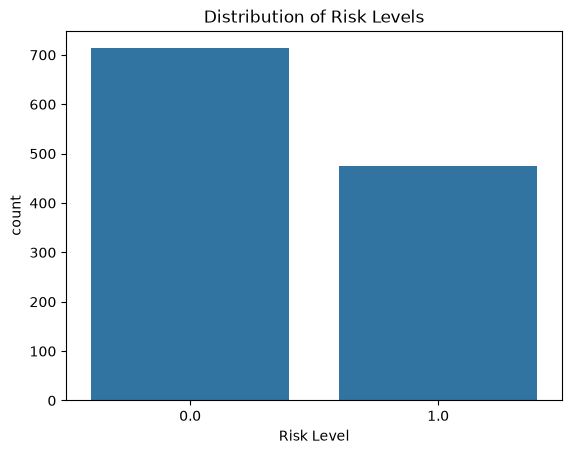

In [10]:
counting = pregnancy["Risk Level"].value_counts()
print(counting)

sns.countplot(x="Risk Level", data=pregnancy, order=counting.index)
plt.title("Distribution of Risk Levels")
plt.show()

### Data-quality summary
**How many records have a missing Risk Level? What percentage of the total data do they represent?**

In [11]:
missing = pregnancy["Risk Level"].isnull().sum()
percent = (missing / rows) * 100
print(f"Missing Risk Level: {duplicate_rows}\npercentage: {percent.round(2)}")

Missing Risk Level: 18
percentage: 1.49


---

## Section 4: Numeric Feature Analysis

### Analytical review of clinically relevant patterns
**Extract complete descriptive statistics (mean, median, standard deviation, quartiles) for all numeric features.**

In [12]:
numeric_features = ["Age", "Systolic BP", "Diastolic", "BS", "Body Temp", "BMI", "Heart Rate"]
pregnancy[numeric_features].describe()

,Age,Systolic BP,Diastolic,BS,Body Temp,BMI,Heart Rate
count,1205.000000,1200.000000,1201.000000,1203.000000,1205.000000,1187.000000,1203.000000
mean,27.482988,116.819167,77.166528,7.501064,98.395851,23.315080,75.817124
std,9.196765,18.715502,14.305148,3.049522,1.088363,3.875682,7.227338
min,10.000000,70.000000,40.000000,3.000000,97.000000,0.000000,58.000000
25%,21.000000,100.000000,65.000000,6.000000,98.000000,20.450000,70.000000
50%,25.000000,120.000000,80.000000,6.900000,98.000000,23.000000,76.000000
75%,31.000000,130.000000,90.000000,7.900000,98.000000,25.000000,80.000000
max,65.000000,200.000000,140.000000,19.000000,103.000000,37.000000,92.000000


### Dataset-level risk summary
**Plot a histogram for each feature. Analyze: shape of distribution, possible skewness.**

- **Age**: We observe a right skew, and the data is concentrated between the ages of 20 and 30, indicating that the majority of mothers fall within this age range.
- **Systolic BP / Diastolic**: In these two charts, it can be observed that the data is more concentrated around round numbers, and both charts exhibit a right skew.
- **BS (blood sugar)**: In the BS chart, we have two sets of data; it can be said that the data are distributed across two different ranges, and a strong right skew is clearly evident.
- **Body Temp**: In this chart, our data is heavily concentrated at a temperature of 98°F, and some mothers also have high fevers.
- **BMI**: Regarding BMI, our data is concentrated between 18 and 30, indicating that the majority of mothers have a normal weight or fall into the overweight category, and the distribution shows a right skew.
- **Heart Rate**: It exhibits slight skewness, and the data is concentrated between 70 and 80 bpm.

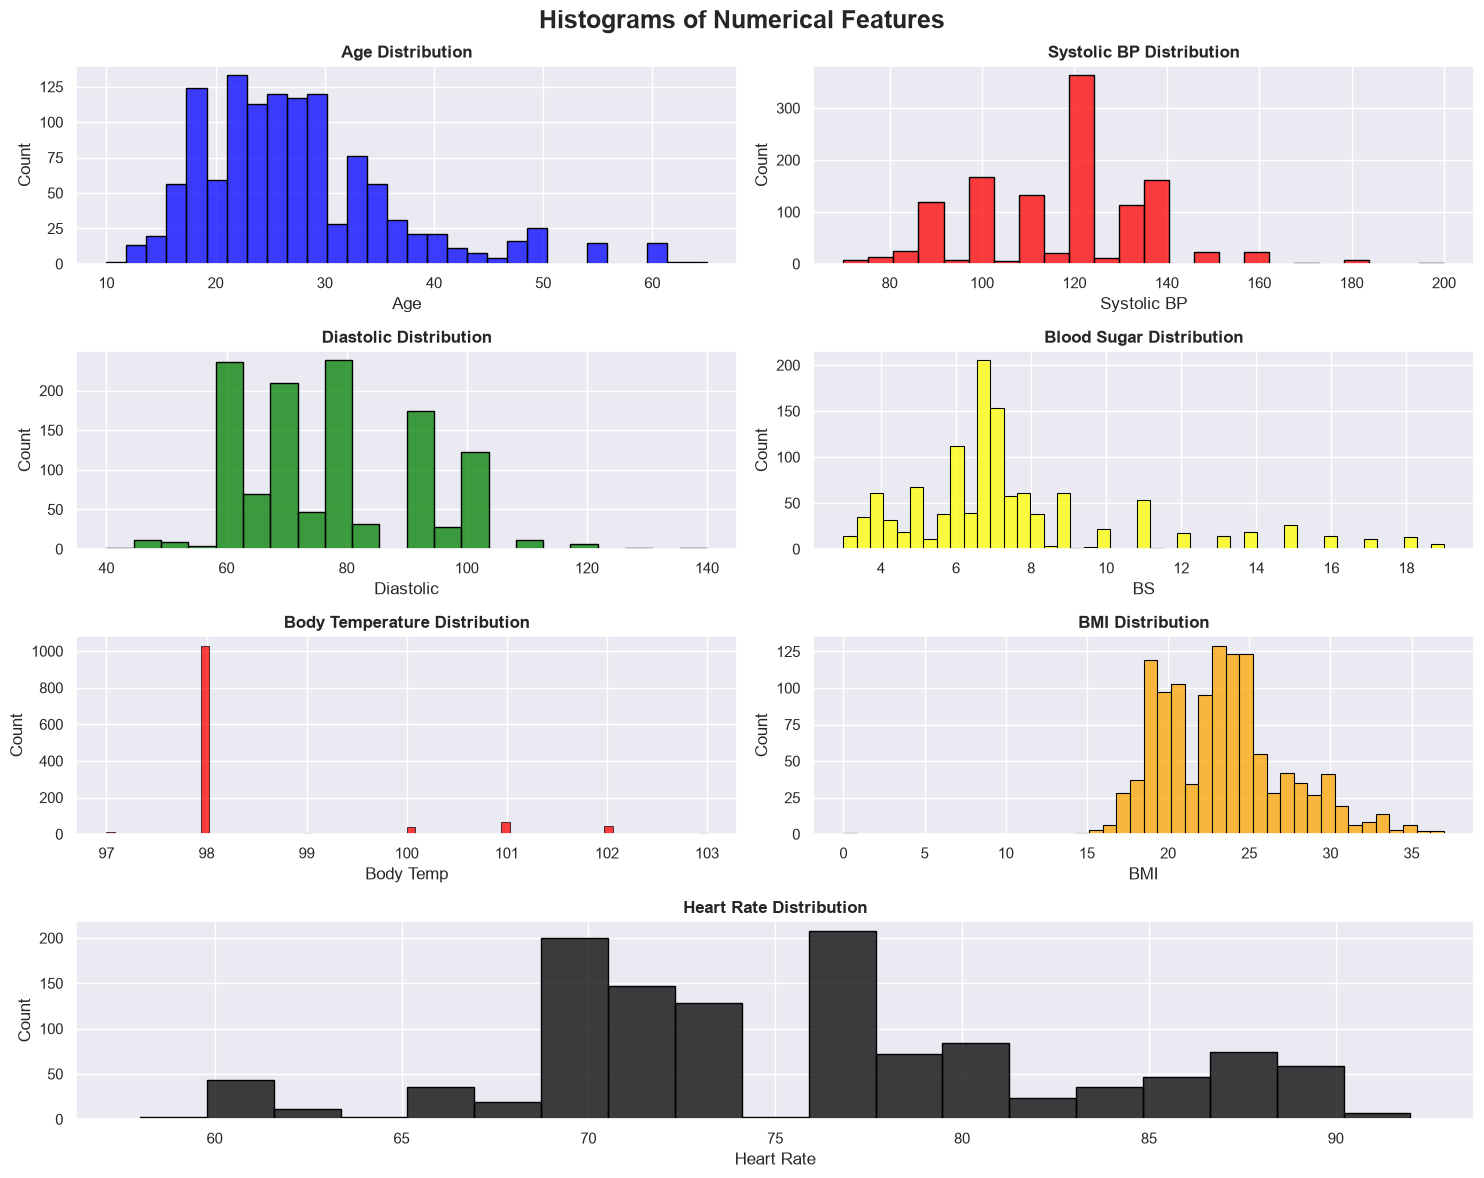

In [13]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 12))

gs = gridspec.GridSpec(4, 2)

fig.suptitle(
    "Histograms of Numerical Features",
    fontsize=18,
    fontweight="bold"
)

ax1 = plt.subplot(gs[0, 0])
sns.histplot(
    x=pregnancy["Age"],
    ax=ax1,
    color="blue",
    edgecolor="black"
)
ax1.set_title("Age Distribution", fontweight="bold")


ax2 = plt.subplot(gs[0, 1])
sns.histplot(
    x=pregnancy["Systolic BP"],
    ax=ax2,
    color="red",
    edgecolor="black"
)
ax2.set_title("Systolic BP Distribution", fontweight="bold")


ax3 = plt.subplot(gs[1, 0])
sns.histplot(
    pregnancy["Diastolic"],
    ax=ax3,
    color="green",
    edgecolor="black"
)
ax3.set_title("Diastolic Distribution", fontweight="bold")


ax4 = plt.subplot(gs[1, 1])
sns.histplot(
    x=pregnancy["BS"],
    ax=ax4,
    color="yellow",
    edgecolor="black"
)
ax4.set_title("Blood Sugar Distribution", fontweight="bold")


ax5 = plt.subplot(gs[2, 0])
sns.histplot(
    x=pregnancy["Body Temp"],
    ax=ax5,
    color="red",
    edgecolor="black"
)
ax5.set_title("Body Temperature Distribution", fontweight="bold")


ax6 = plt.subplot(gs[2, 1])
sns.histplot(
    x=pregnancy["BMI"],
    ax=ax6,
    color="orange",
    edgecolor="black"
)
ax6.set_title("BMI Distribution", fontweight="bold")

ax7 = plt.subplot(gs[3, :])
sns.histplot(
    x=pregnancy["Heart Rate"],
    ax=ax7,
    color="black",
    edgecolor="black"
)
ax7.set_title("Heart Rate Distribution", fontweight="bold")

plt.tight_layout()
plt.show()

### Feature engineering context
**Plot a boxplot for each feature and identify outliers.**

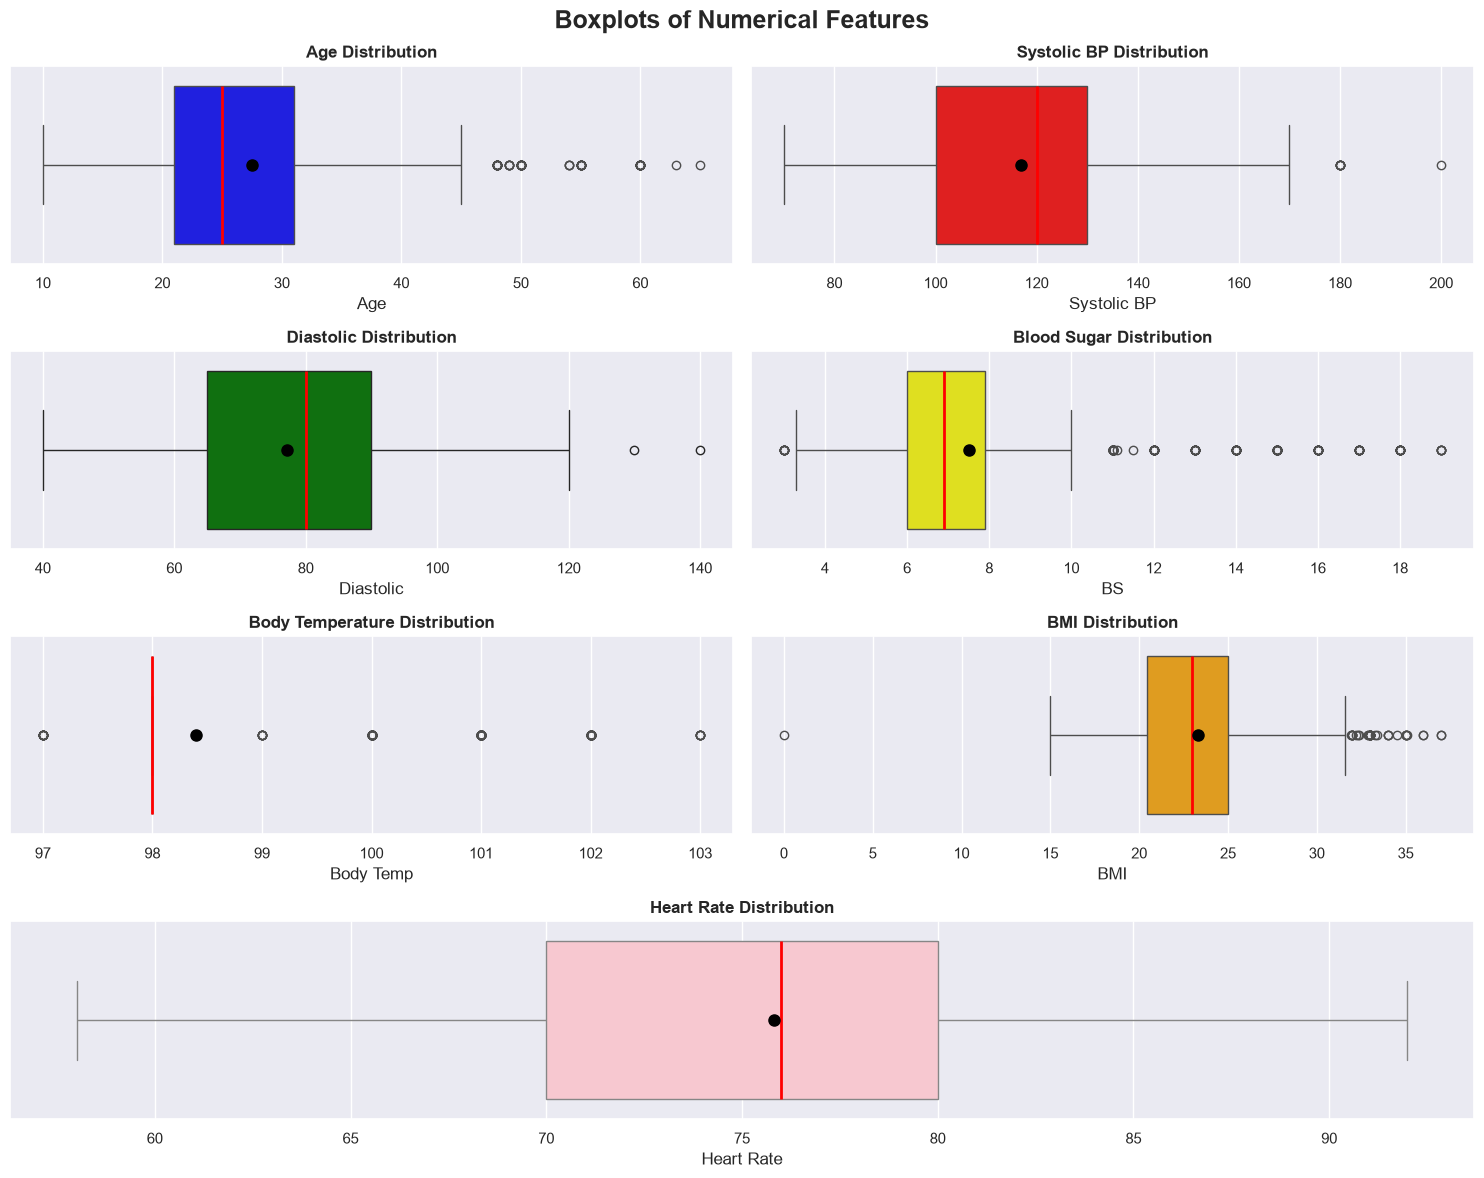

In [29]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 12))

gs = gridspec.GridSpec(4, 2)

fig.suptitle(
    "Boxplots of Numerical Features",
    fontsize=18,
    fontweight="bold"
)

median_props = {
    "color": "red",
    "linewidth": 2
}
mean_props = {
    "marker": "o",
    "markerfacecolor": "black",
    "markeredgecolor": "black",
    "markersize": 8
}


ax1 = plt.subplot(gs[0, 0])
sns.boxplot(
    x=pregnancy["Age"],
    ax=ax1,
    color="blue",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax1.set_title("Age Distribution", fontweight="bold")


ax2 = plt.subplot(gs[0, 1])
sns.boxplot(
    x=pregnancy["Systolic BP"],
    ax=ax2,
    color="red",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax2.set_title("Systolic BP Distribution", fontweight="bold")


ax3 = plt.subplot(gs[1, 0])
sns.boxplot(
    x=pregnancy["Diastolic"],
    ax=ax3,
    color="green",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax3.set_title("Diastolic Distribution", fontweight="bold")


ax4 = plt.subplot(gs[1, 1])
sns.boxplot(
    x=pregnancy["BS"],
    ax=ax4,
    color="yellow",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax4.set_title("Blood Sugar Distribution", fontweight="bold")


ax5 = plt.subplot(gs[2, 0])
sns.boxplot(
    x=pregnancy["Body Temp"],
    ax=ax5,
    color="red",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax5.set_title("Body Temperature Distribution", fontweight="bold")


ax6 = plt.subplot(gs[2, 1])
sns.boxplot(
    x=pregnancy["BMI"],
    ax=ax6,
    color="orange",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax6.set_title("BMI Distribution", fontweight="bold")

ax7 = plt.subplot(gs[3, :])
sns.boxplot(
    x=pregnancy["Heart Rate"],
    ax=ax7,
    color="pink",
    showmeans=True,
    medianprops=median_props,
    meanprops=mean_props
)
ax7.set_title("Heart Rate Distribution", fontweight="bold")

plt.tight_layout()
plt.show()

In [15]:
for column in numeric_features:
    q1 = pregnancy[column].quantile(0.25)
    q3 = pregnancy[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = pregnancy[
        (pregnancy[column] < lower_bound)
        | (pregnancy[column] > upper_bound)
    ]
    print(f"{column} => {len(outliers)} outliers.")

Age => 73 outliers.
Systolic BP => 8 outliers.
Diastolic => 2 outliers.
BS => 181 outliers.
Body Temp => 175 outliers.
BMI => 37 outliers.
Heart Rate => 0 outliers.



### Clinical range audit
**Does the range of values for each feature align with recognized clinical thresholds?**

Since our dataset contains outliers, not all data points fall within the normal range; however, a portion of the data does cover the normal range, representing our core data.

In [16]:
numeric = numeric_features.copy()
numeric.remove("Age")
min_max = []
for column in numeric:
    result = f"{pregnancy[column].min()}-{pregnancy[column].max()}"
    min_max.append(result)

normal_ranges = {
    "Systolic BP": "90-120",
    "Diastolic": "60-80",
    "BS": "3.9-5.5",
    "Body Temp": "97-99",
    "BMI": "18.5-24.9",
    "Heart Rate": "60-100",
}
value_check = pd.DataFrame({
    "Features": numeric,
    "Normal Range": [normal_ranges[f] for f in numeric],
    "DataSet Range": min_max,
})
value_check

,Features,Normal Range,DataSet Range
0,Systolic BP,90-120,70.0-200.0
1,Diastolic,60-80,40.0-140.0
2,BS,3.9-5.5,3.0-19.0
3,Body Temp,97-99,97-103
4,BMI,18.5-24.9,0.0-37.0
5,Heart Rate,60-100,58.0-92.0


---

## Section 5: Binary Feature Analysis

### Variable-level observations
**Calculate the frequency of each category and display with a countplot.**


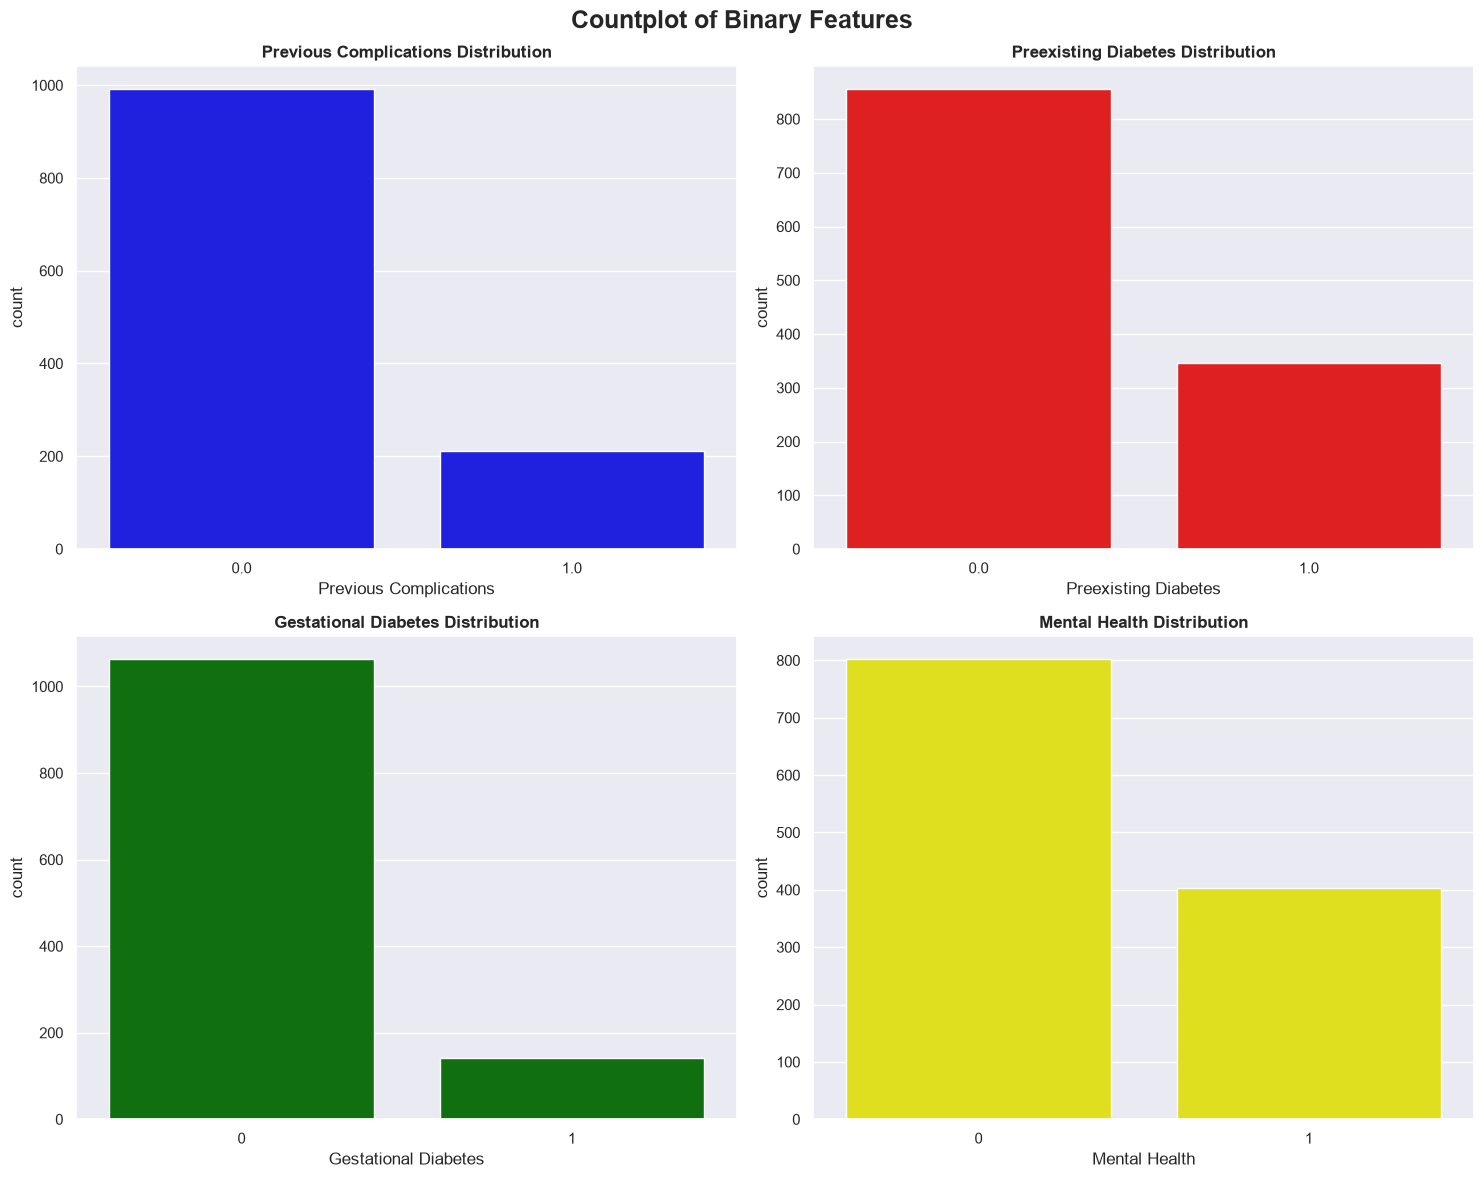

In [17]:
binary_features = [
    "Previous Complications", "Preexisting Diabetes",
    "Gestational Diabetes", "Mental Health"
]

sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 12))

gs = gridspec.GridSpec(2, 2)

fig.suptitle(
    "Countplot of Binary Features",
    fontsize=18,
    fontweight="bold"
)

ax1 = plt.subplot(gs[0, 0])
sns.countplot(
    x=pregnancy["Previous Complications"],
    ax=ax1,
    color="blue"
)
ax1.set_title("Previous Complications Distribution", fontweight="bold")


ax2 = plt.subplot(gs[0, 1])
sns.countplot(
    x=pregnancy["Preexisting Diabetes"],
    ax=ax2,
    color="red",
)
ax2.set_title("Preexisting Diabetes Distribution", fontweight="bold")


ax3 = plt.subplot(gs[1, 0])
sns.countplot(
    x=pregnancy["Gestational Diabetes"],
    ax=ax3,
    color="green",
)
ax3.set_title("Gestational Diabetes Distribution", fontweight="bold")


ax4 = plt.subplot(gs[1, 1])
sns.countplot(
    x=pregnancy["Mental Health"],
    ax=ax4,
    color="yellow",
)
ax4.set_title("Mental Health Distribution", fontweight="bold")

plt.tight_layout()
plt.show()

In [18]:
for column in binary_features:
    print(pregnancy[column].value_counts(dropna=False))
    print()

Previous Complications
0.0    992
1.0    211
NaN      2
Name: count, dtype: int64

Preexisting Diabetes
0.0    856
1.0    347
NaN      2
Name: count, dtype: int64

Gestational Diabetes
0    1063
1     142
Name: count, dtype: int64

Mental Health
0    802
1    403
Name: count, dtype: int64



### Summary of dataset findings
**How many patients have none of the medical flags at all? How many have all of them simultaneously?**

In [19]:
flags = []

for index, row in pregnancy.iterrows():
    count = 0
    for feature in binary_features:
        if row[feature] == 1:
            count += 1
    
    flags.append(count)
flags = np.array(flags)

zero_flags = (flags == 0).sum()
all_flags = (flags == len(binary_features)).sum()

print(f"Patients with NO flags at all: {zero_flags}")
print(f"Patients with ALL {len(binary_features)} flags simultaneously: {all_flags}")

Patients with NO flags at all: 641
Patients with ALL 4 flags simultaneously: 7


### Summary of feature relevance
**Is there correlation among the medical flags themselves (with each other, not with the target)?**


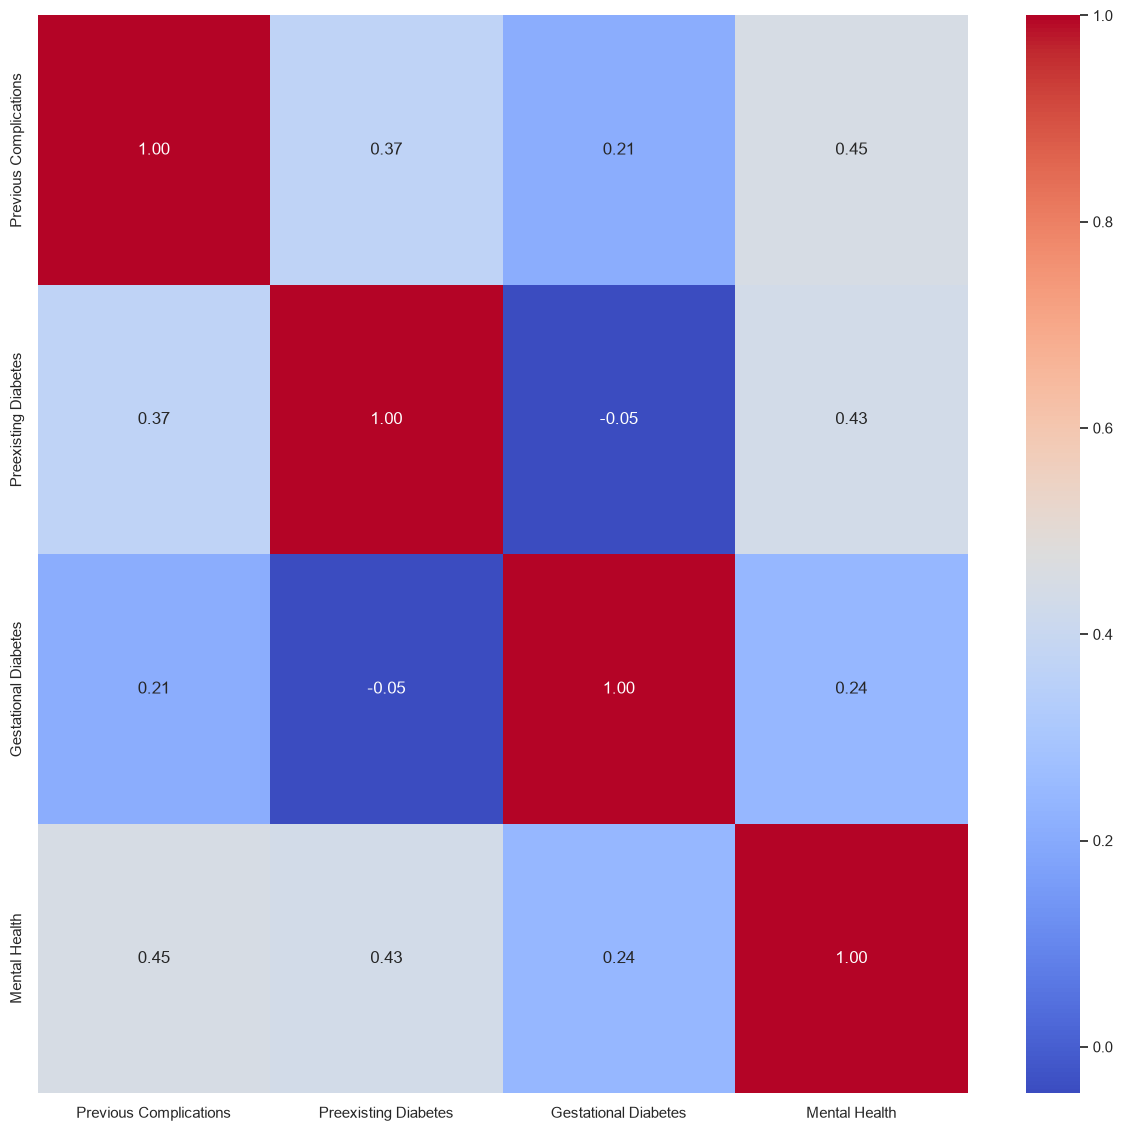

In [20]:
bin_corr = pregnancy[binary_features].corr()
plt.figure(figsize=(15, 14))
sns.heatmap(
    data=bin_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()

---

## Section 6: Relationship Between Features and Risk Level

### Summary of data quality and risk signals
**compare the distribution of all numeric features based on Risk Level.**

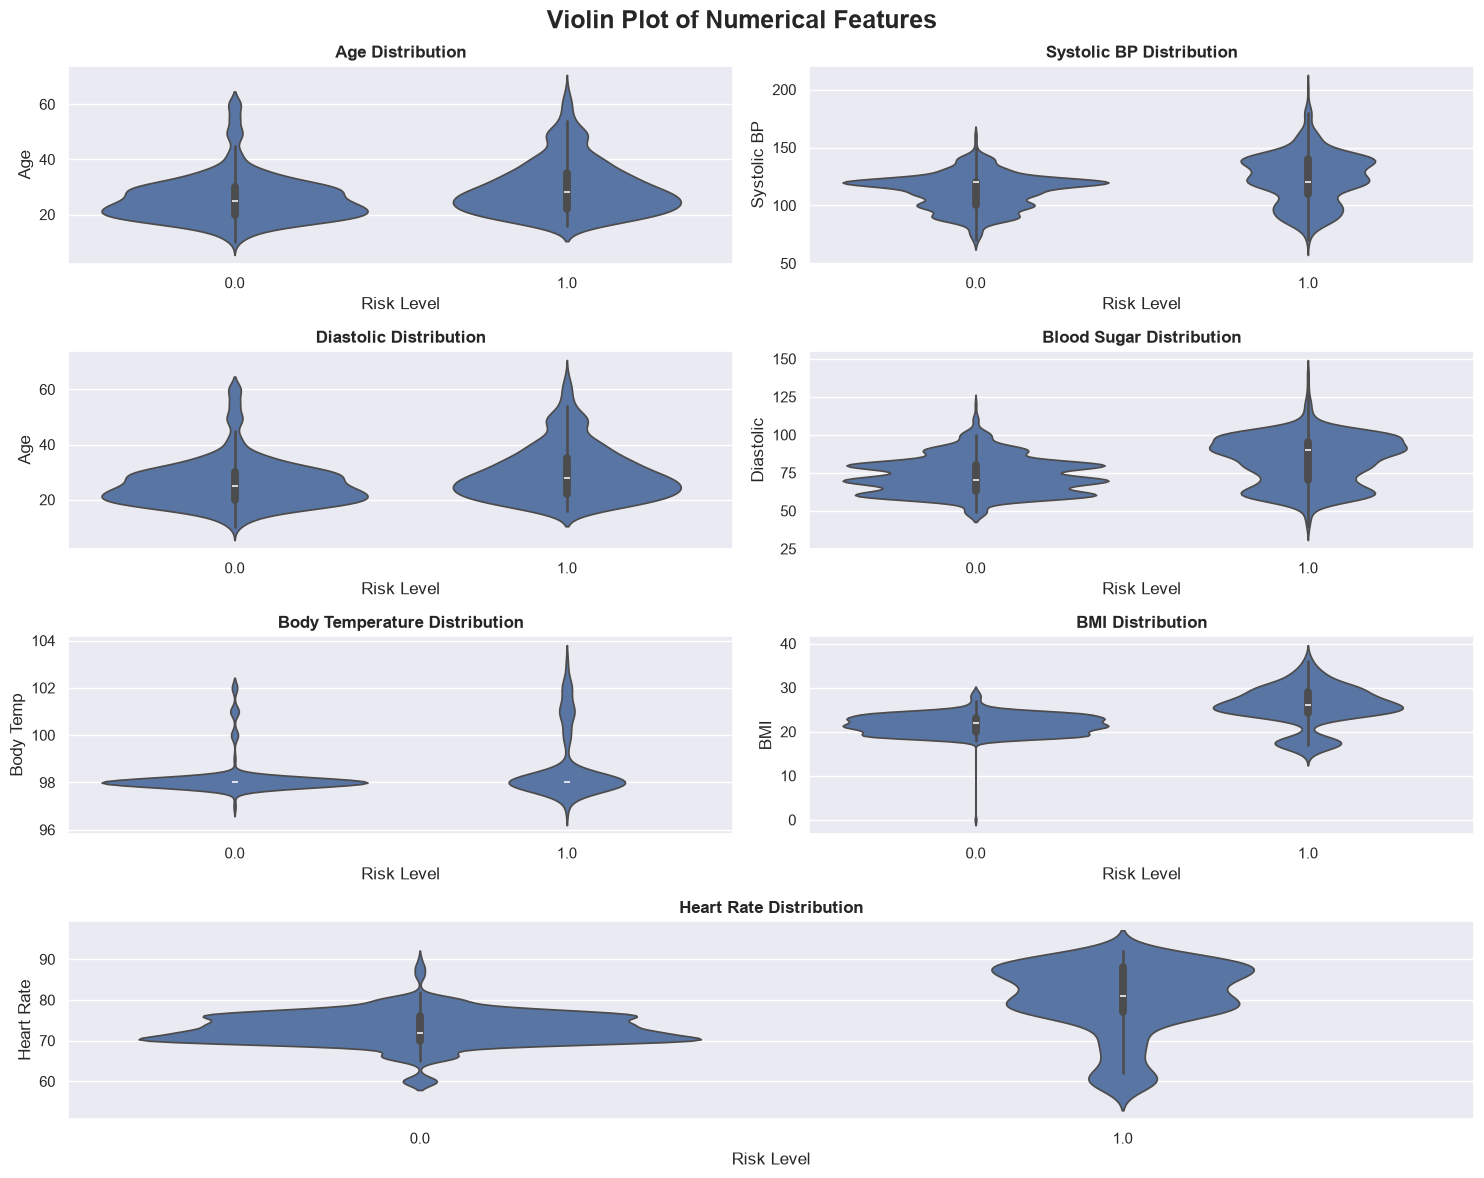

In [21]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(15, 12))

gs = gridspec.GridSpec(4, 2)

fig.suptitle(
    "Violin Plot of Numerical Features",
    fontsize=18,
    fontweight="bold"
)

ax1 = plt.subplot(gs[0, 0])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="Age",
    ax=ax1,
)
ax1.set_title("Age Distribution", fontweight="bold")


ax2 = plt.subplot(gs[0, 1])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="Systolic BP",
    ax=ax2,
)
ax2.set_title("Systolic BP Distribution", fontweight="bold")


ax3 = plt.subplot(gs[1, 0])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="Age",
    ax=ax3,
)
ax3.set_title("Diastolic Distribution", fontweight="bold")


ax4 = plt.subplot(gs[1, 1])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="Diastolic",
    ax=ax4,
)
ax4.set_title("Blood Sugar Distribution", fontweight="bold")


ax5 = plt.subplot(gs[2, 0])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="Body Temp",
    ax=ax5,
)
ax5.set_title("Body Temperature Distribution", fontweight="bold")


ax6 = plt.subplot(gs[2, 1])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="BMI",
    ax=ax6,
)
ax6.set_title("BMI Distribution", fontweight="bold")

ax7 = plt.subplot(gs[3, :])
sns.violinplot(
    data=pregnancy,
    x="Risk Level",
    y="Heart Rate",
    ax=ax7,
)
ax7.set_title("Heart Rate Distribution", fontweight="bold")

plt.tight_layout()
plt.show()

### Feature interpretation and next steps
**For each key numeric feature, bin the data into clinically meaningful ranges and calculate `the percentage of High-risk cases in each bin`, to identify the threshold point where risk sharply jumps.**

`Age:`Based on these findings, the risk of pregnancy increases from age 32 onwards, peaking between the ages of 43 and 54. The oldest bin (54–65) shows a drop to 41.4%, but this is based on only 29 patients and is likely noise from a small sample rather than a genuine decline in risk — it should not be read as pregnancy becoming safer after 54.

`Systolic BP:`Based on this output, it can be said that as the value of this field increases, the percentage of low-risk pregnancies decreases.

`Diastolic:`Based on this output, the peak of our high-risk data begins at the 80 mark, and the pregnancy risk is extremely high for mothers whose diastolic blood pressure is at this level.

`Blood Sugar:`In this area, too, the higher the blood sugar level, the greater the risk of a high-risk pregnancy; the peak of this risk begins at 9.4.

`BMI:`The output shows that in people who are overweight, the risk of high-risk pregnancy is very high and the peak of high-risk data is from BMI greater than 22.

`Heart Rate:`Our low-risk data falls within the 64–78 range, which is normal; we have a small number of high-risk pregnancies, and heart rates falling outside this range increase the risk.

In [22]:
def threshold(column):
    temp = pregnancy.copy()
    temp["bin"] = pd.cut(temp[column], bins=5)

    result = temp.groupby("bin")["Risk Level"].agg(["mean", "count"])

    result["mean"] = (result["mean"] * 100).round(1)
    result.columns = ["High-risk", "quantity"]
    return result

temp_numeric = numeric_features.copy()
temp_numeric.remove("Body Temp")
for column in temp_numeric:
    print(f"\n{column}")
    print(threshold(column))



Age
               High-risk  quantity
bin                               
(9.945, 21.0]       28.3       329
(21.0, 32.0]        38.1       606
(32.0, 43.0]        59.9       172
(43.0, 54.0]        68.6        51
(54.0, 65.0]        41.4        29

Systolic BP
                High-risk  quantity
bin                                
(69.87, 96.0]        37.4       171
(96.0, 122.0]        26.6       674
(122.0, 148.0]       63.9       285
(148.0, 174.0]       91.1        45
(174.0, 200.0]      100.0         8

Diastolic
                High-risk  quantity
bin                                
(39.9, 60.0]         31.2       256
(60.0, 80.0]         25.2       556
(80.0, 100.0]        67.9       355
(100.0, 120.0]       68.8        16
(120.0, 140.0]      100.0         2

BS
              High-risk  quantity
bin                              
(2.984, 6.2]       16.0       382
(6.2, 9.4]         36.2       610
(9.4, 12.6]        97.9        94
(12.6, 15.8]       98.2        57
(15.8, 19.0]  

### Variable signal review
**For all binary features , create a single comprehensive cross-tab with Risk Level.**

In [23]:
from IPython.display import display


for column in binary_features:
    display(
        pd.crosstab(
            pregnancy[column],
            pregnancy["Risk Level"]
        )
    )

Risk Level,0.0,1.0
Previous Complications,,
0.0,707,269
1.0,6,204


Risk Level,0.0,1.0
Preexisting Diabetes,,
0.0,687,155
1.0,26,318


Risk Level,0.0,1.0
Gestational Diabetes,,
0,713,334
1,0,140


Risk Level,0.0,1.0
Mental Health,,
0,649,140
1,64,334


### Dataset synthesis
**Is there a near-perfect (close to 100%) relationship between Gestational Diabetes or BMI≥30 and Risk Level? Does this indicate a genuinely very strong clinical relationship, or should the possibility of `Target Leakage` be investigated?**

No matter how significant these two medical factors may be, they are not the sole determinants; other characteristics are also important. Given the output in both fields—wherever they are present—100% of our data points are classified as high-risk pregnancies, suggesting the likely presence of target leakage.

In [24]:
print("Gestational Diabetes vs Risk Level:")
print((pd.crosstab(pregnancy['Gestational Diabetes'], pregnancy['Risk Level'], normalize='index')*100).round(2))
print()
print("BMI >= 30 vs Risk Level:")
print((pd.crosstab(pregnancy['BMI'] >= 30, pregnancy['Risk Level'], normalize='index')*100).round(2))

Gestational Diabetes vs Risk Level:
Risk Level             0.0    1.0
Gestational Diabetes             
0                     68.1   31.9
1                      0.0  100.0

BMI >= 30 vs Risk Level:
Risk Level    0.0     1.0
BMI                      
False       64.52   35.48
True         0.00  100.00


---

## Section 7: Relationships Between Features

### Feature and target review
**Calculate the correlation matrix between all numeric and binary features, and plot it as a Heatmap.**

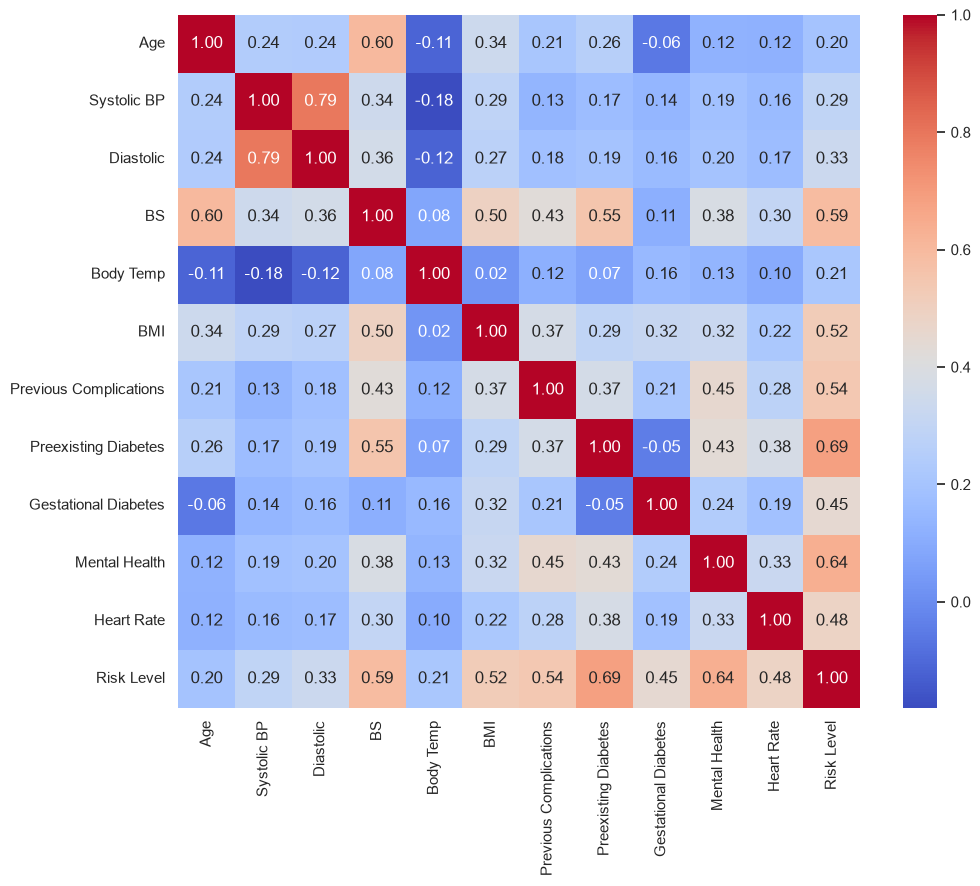

In [25]:
correlation = pregnancy.corr()
plt.figure(figsize=(11, 9))
sns.heatmap(
    data=correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.show()


### Analytical summary
**Which features have the strongest positive correlation with Risk Level?**

Ranked by actual correlation strength (strongest first):

- Preexisting Diabetes (0.69)
- Mental Health (0.64)
- BS (0.59)
- Previous Complications (0.54)
- BMI (0.52)

### Data-quality interpretation
**Find the three pairs of features with the highest correlation with each other (not with the target).**

- Systolic BP & Diastolic
- BS & Age
- BS & Preexisting Diabetes

### Risk-factor interpretation
**Plot a scatter plot between at least two important feature pairs , colored by Risk Level.**

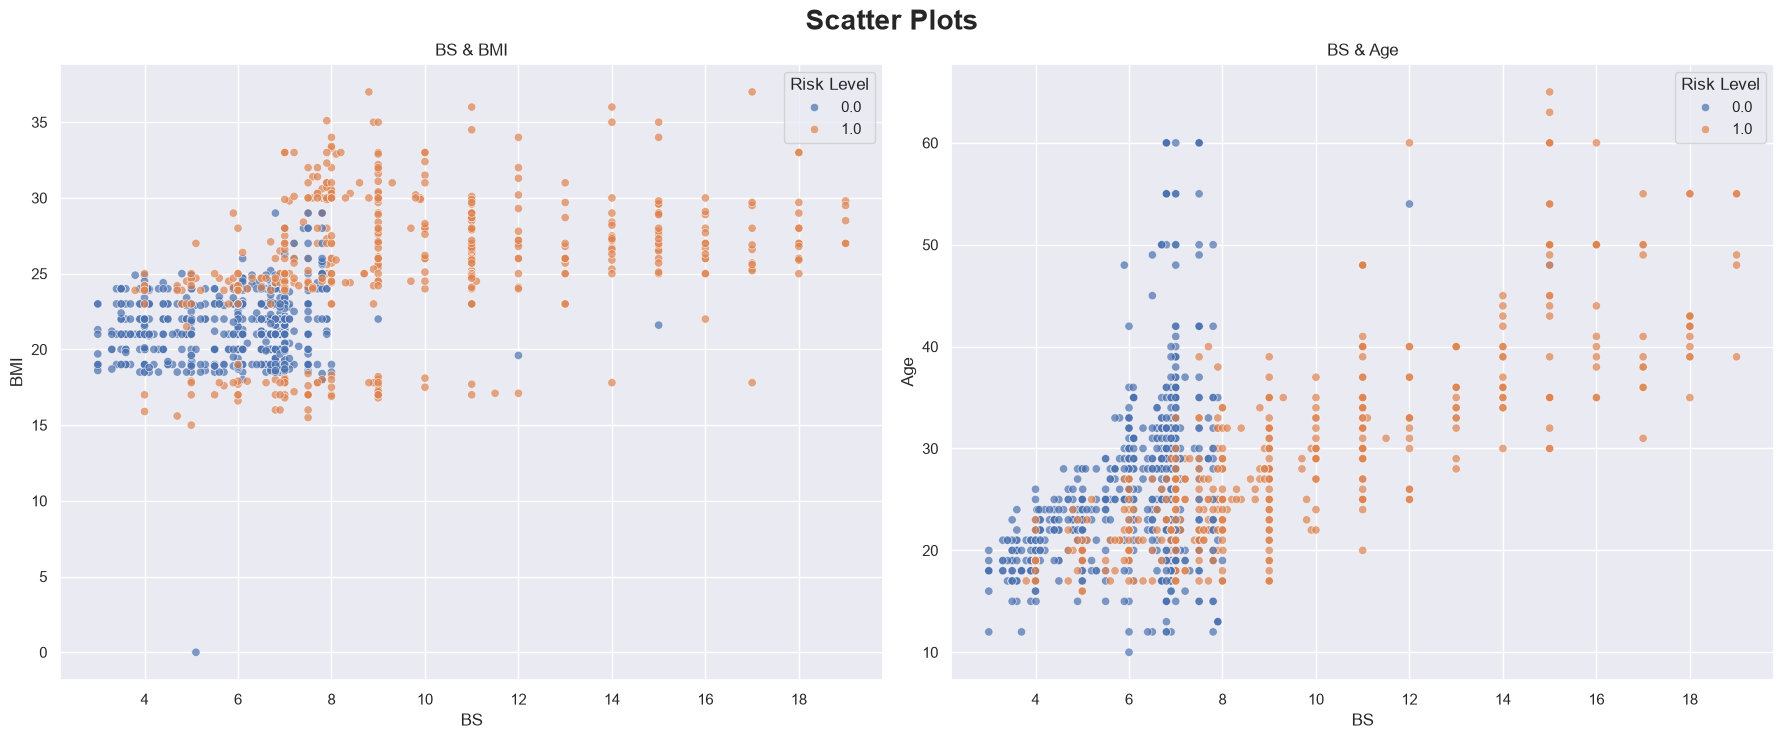

In [26]:
sns.set_theme(style="darkgrid")

fig = plt.figure(figsize=(18, 14))

gs = gridspec.GridSpec(2, 2)

fig.suptitle(
    "Scatter Plots",
    fontsize=20,
    fontweight="bold"
)


ax1 = plt.subplot(gs[0, 0])
sns.scatterplot(
    data=pregnancy,
    x="BS",
    y="BMI",
    hue="Risk Level",
    alpha=0.7,
    ax=ax1
)
ax1.set_title("BS & BMI")


ax2 = plt.subplot(gs[0, 1])
sns.scatterplot(
    data=pregnancy,
    x="BS",
    y="Age",
    hue="Risk Level",
    alpha=0.7,
    ax=ax2
)
ax2.set_title("BS & Age")

plt.tight_layout()
plt.show()

### Analytical review**Calculate the probability of being High-risk for different combinations of risk factors:**
- **No risk factors at all**
- **Only one risk factor**
- **A combination of two or more risk factors simultaneously**

In [27]:
pregnancy["qty_risk"] = pregnancy[binary_features].sum(axis=1)

multi = pregnancy.groupby("qty_risk")["Risk Level"].agg(["mean", "count"])
multi["mean"] = (multi["mean"] * 100).round(2)
multi.columns = ["High-risk", "patients"]
multi

,High-risk,patients
qty_risk,,
0.0,0.79,632
1.0,57.84,185
2.0,97.14,210
3.0,98.69,153
4.0,100.00,7


### Risk summary
**Extract three patient profiles based purely on observation of the data: low-risk, borderline-risk, high-risk.**

**Low Risk:**
- `Age:` 19
- `BMI:` 22.3
- `Blood Sugar:` 5.8
- `Systolic BP:` 108
- `Diastolic BP:` 68
- `Heart Rate:` 70
- `Gestational Diabetes:` No

**Border Line:**
- `Age:` 27
- `BMI:` 26.8
- `Blood Sugar:` 7.2
- `Systolic BP:` 122
- `Diastolic BP:` 82
- `Heart Rate:` 80
- `Gestational Diabetes:` No

**High Risk:**
- `Age:` 36
- `BMI:` 32.5
- `Blood Sugar:` 9.8
- `Systolic BP:` 142
- `Diastolic BP:` 95
- `Heart Rate:` 90
- `Gestational Diabetes:` Yes

---

## Final Report

**1. Which features are most likely to be associated with high-risk pregnancy?**

- Blood Sugar
- BMI
- Systolic/Diastolic BP
- Preexisting Diabetes
- Gestational Diabetes 
- Previous Complications 
- Mental Health

**2. Which features are likely to have greater value for future modeling?**

Blood glucose, systolic/diastolic blood pressure, and body mass index (BMI) are at clear clinical thresholds. Pre-existing or gestational diabetes and a BMI ≥30 require caution due to concerns regarding leakage.

**3. What data quality issues were observed?**

Throughout this file, data quality was checked. We have both missing data and outliers.

**4. Was there any indication of Target Leakage in some features?**

Yes. `Gestational Diabetes` and `BMI ≥ 30` each show a near-100% deterministic relationship with Risk Level (Section 6), which is a strong empirical signal of target leakage. This does not mean the underlying clinical relationship is false — these factors are genuinely influential in reality. Clinical validity and target leakage are not mutually exclusive: a feature can be both clinically real and a leakage risk at the same time, because leakage is about *when* information becomes available, not whether it is true. Per the Prediction-Time Availability Rule (Business Understanding, Section 4.2), `Gestational Diabetes` is diagnosed within the same clinical process that determines Risk Level, so it must be excluded from the deployable, leakage-excluded model and retained only in a leakage-inclusive comparison used to quantify its effect.

**5. Is the data ready to enter the Data Preparation phase?**

Yes.

### Additional analytical review

**Audit the Clinical Range vs Dataset Range table produced in the "Clinical range audit" section and confirm each value now matches the correct feature and unit. Briefly document what was wrong before the fix.**

The table now uses feature-keyed ranges: blood pressure is in mmHg, BS is fasting mmol/L, Body Temperature is Fahrenheit, BMI is kg/m², and Heart Rate is beats per minute. Previously the positional list shifted the BS, Body Temp, BMI, and Heart Rate ranges.

### Additional interpretation

**Classify each IQR outlier as a statistical outlier only or clinically implausible, and explain the handling decision.**

In [28]:
outlier_rows = []
for feature in numeric_features:
    q1, q3 = pregnancy[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    bounds = (q1 - 1.5 * iqr, q3 + 1.5 * iqr)
    count = ((pregnancy[feature] < bounds[0]) | (pregnancy[feature] > bounds[1])).sum()
    category = "Clinically implausible" if feature == "BMI" and (pregnancy[feature] <= 0).any() else "Statistical outlier only"
    decision = "Remove or investigate impossible measurements" if category == "Clinically implausible" else "Retain; verify clinically and do not winsorize automatically"
    outlier_rows.append({"Feature": feature, "IQR outliers": count, "Category": category, "Handling": decision})
pd.DataFrame(outlier_rows)

,Feature,IQR outliers,Category,Handling
0,Age,73,Statistical outlier only,Retain; verify clinically and do not winsorize...
1,Systolic BP,8,Statistical outlier only,Retain; verify clinically and do not winsorize...
2,Diastolic,2,Statistical outlier only,Retain; verify clinically and do not winsorize...
3,BS,181,Statistical outlier only,Retain; verify clinically and do not winsorize...
4,Body Temp,175,Statistical outlier only,Retain; verify clinically and do not winsorize...
5,BMI,37,Clinically implausible,Remove or investigate impossible measurements
6,Heart Rate,0,Statistical outlier only,Retain; verify clinically and do not winsorize...


### Final data-understanding synthesis

**Document the measurement condition, unit system, and dataset-vs-assumption status for every clinical threshold used in this notebook.**

Thresholds such as BP ≥140/90 mmHg, BS ≥7.5 or ≥9, BMI ?30 kg/m², and temperature 97–99°F are clinical assumptions unless the raw dataset explicitly records the measurement condition. In particular, fasting versus non-fasting BS and the temperature unit are not fully specified in the raw file; these assumptions are limitations and should be confirmed before clinical use.